# Kwantyzacja

Kwantyzacja - technika stosowana w uczeniu maszynowym do optymalizacji.

Polega na zmniejszeniu precyzji parametrów (= wag i aktywacji). Przekształcamy wartości o wysokiej precyzji np FP32 do formatu o niższej precyzji np INT8

Po co kwantyzacja:
- zmniejszenie potrzebnej pamięci do przechowywania modelu
- szybsze obliczenia
- mniejsze zużycie energii
a wszystko to przekłąda się na koszta.

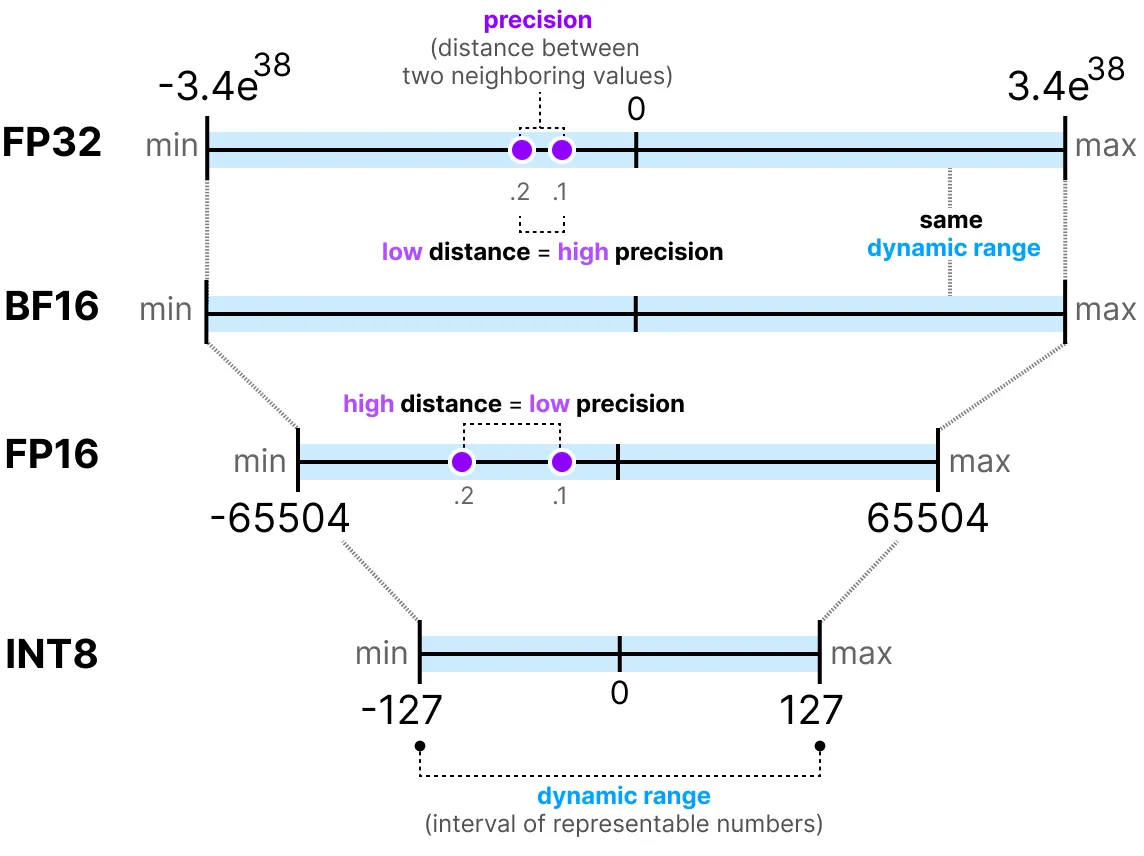

Przykład: FP32 na INT8


1. Znajdujemy zakres wartości

Szukamy w jakim zakresie są nasze wartości - czyli potrzebujemy min i max.

Np min: -0.23 oraz max 0.18

2. Obliczamy skalę

Int8 = 8 bitów moze reprezentować 256 wartości = zakres od 0 do 255

Przeliczamy skalę czyli jeden krok INT8 odpowiada jakiej części kroku w rzeczywistości (FP32).

```
scale = (max_fp32 - min_fp32) / (max_range_int8 - min_range_int8)
scale = (0.18 - -0.23) / (255 - 0)
scale = 0.41 / 255
scale ≈ 0.0016
```

1 krok INT8 to około 0.0016 kroku FP32 (dla naszego fikcyjnego przykładu)

3. Znajdujemy zero-point

Patrzymy gdzie umieścić zero z wartości FP32 na osi INT8

Dla zakresu -0.23 : 0.18 środek nie wypadnie dokładnie w 0

```
zero_point = round( (0 − (–0.23)) / 0.0016 )
           = round( 0.23 / 0.0016 )
           ≈ round(143.0)
           = 143
```

Teraz mozemy powiedzieć że 0 w FP32 będzie dla INT8 zakodowane jako 143

Podsumowanie:
| float | INT8 |
| ----- | ---- |
| –0.23 | 0    |
| 0     | 143  |
| 0.18  | 255  |

4. Kwantyzacja

Skoro wiemy jak wygląda nasz nowy zakres możemy przeliczyć każdą wartość na INT8

`x_int8 = round(x_fp32 / scale + zero_point)`


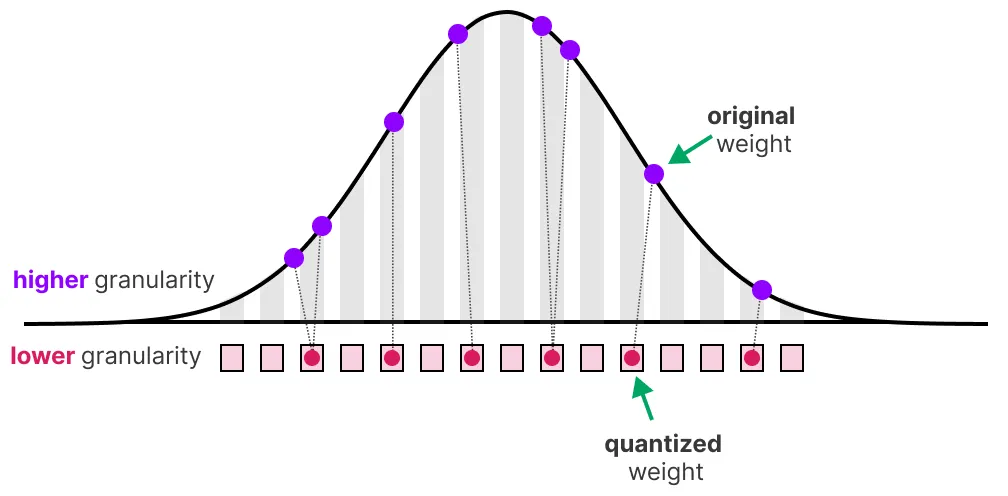

## Symetryczna vs asymetryczna kwantyzacja

Symetryczna - zachowujemy punkt zero w miejscu rzeczywistym

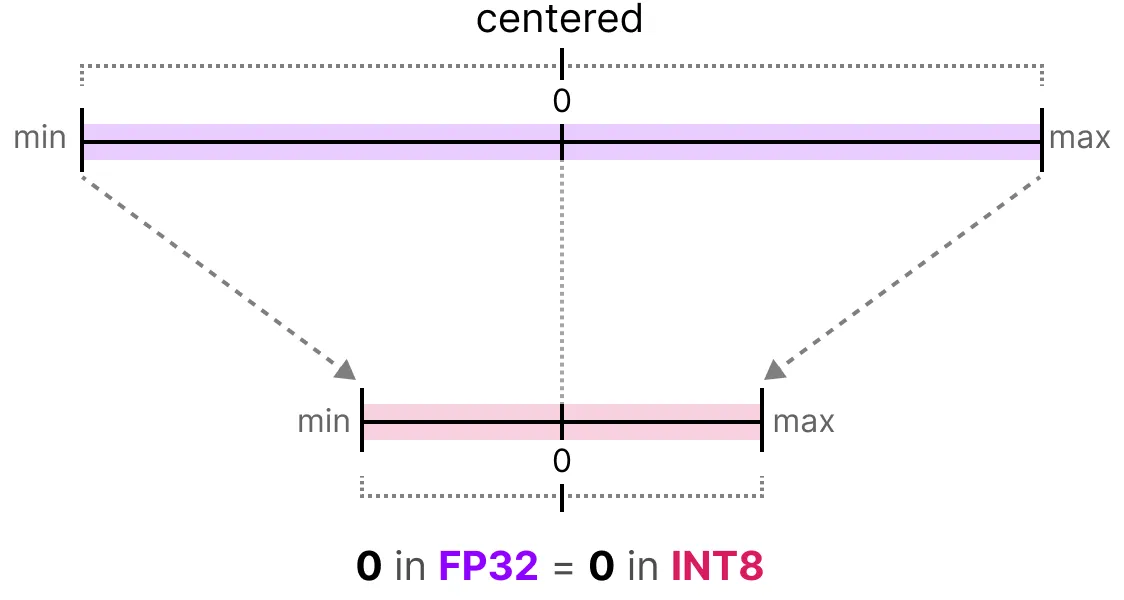

Asymetryczna - środek między minimum i maksimum. Sugerowana jeśli nasze wartości są przesunięte w którąś stronę.

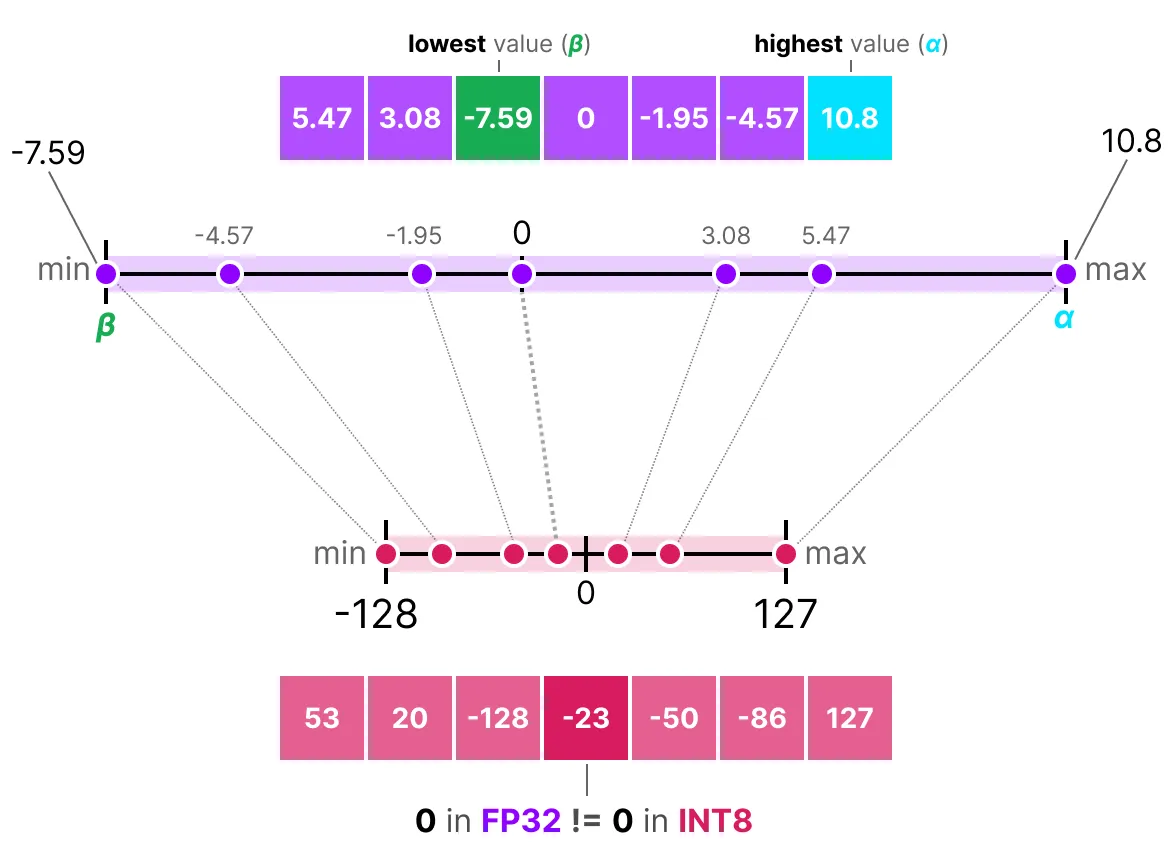

Error kwantyzacji:
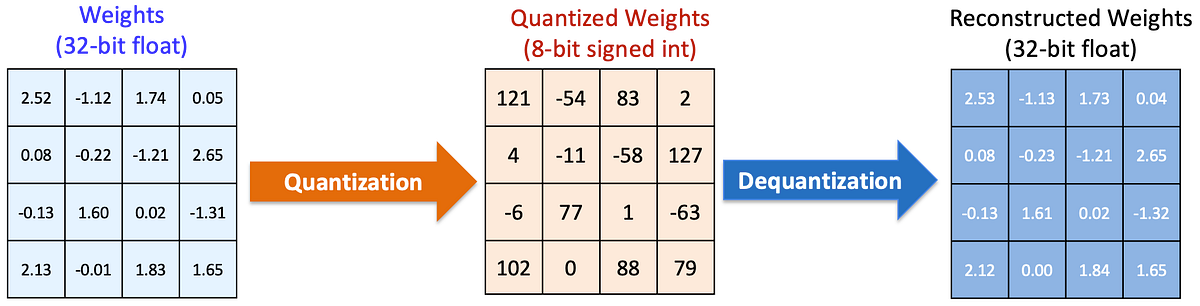

Clipping

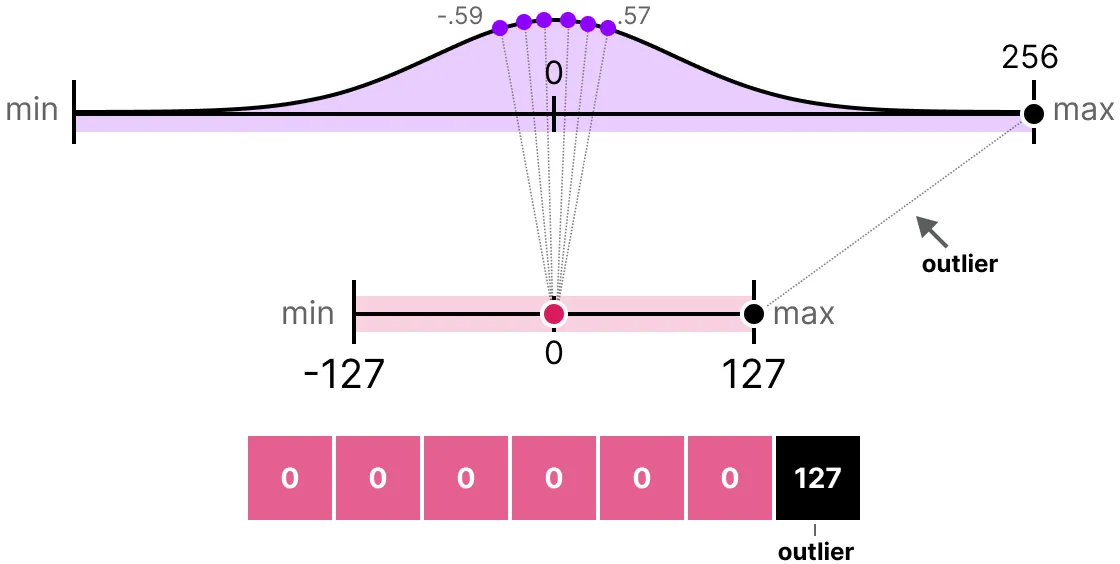
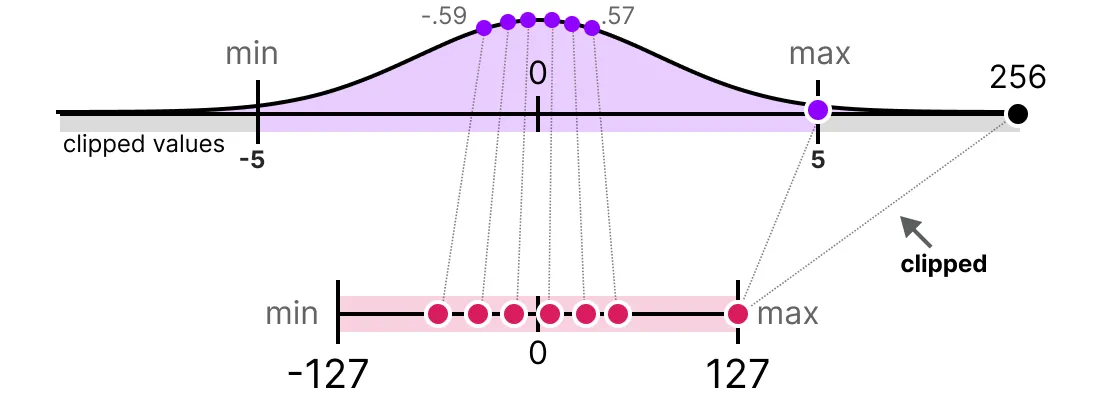

## Przygotowanie środowiska

In [1]:
!pip install -q transformers accelerate bitsandbytes datasets huggingface_hub torch

In [2]:
import torch
torch.backends.mps.is_available()

True

## Ładowanie modelu bazowego

Weźmiemy ogólnodostepną wersję llamy 3.2-3B: https://huggingface.co/chuanli11/Llama-3.2-3B-Instruct-uncensored

Użyjemy do tego funkcji `snapshot_download`

In [3]:
from huggingface_hub import snapshot_download

model_name = "chuanli11/Llama-3.2-3B-Instruct-uncensored"
snapshot_download(repo_id=model_name, local_dir="Llama3.2")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

'/Users/mirya/Desktop/PJATK/PJATK_Projects/NLP_PJN/08/Llama3.2'

In [1]:
!ls -lash Llama3.2

total 14106904
      0 drwxr-xr-x@ 13 mirya  staff   416B Nov 24 18:53 .
      0 drwxr-xr-x@  7 mirya  staff   224B Nov 24 19:05 ..
      0 drwxr-xr-x@  3 mirya  staff    96B Nov 24 18:43 .cache
      8 -rw-r--r--@  1 mirya  staff   1.5K Nov 24 18:43 .gitattributes
     16 -rw-r--r--@  1 mirya  staff   4.9K Nov 24 18:43 README.md
      8 -rw-r--r--@  1 mirya  staff   928B Nov 24 18:43 config.json
      8 -rw-r--r--@  1 mirya  staff   189B Nov 24 18:43 generation_config.json
9698832 -rw-r--r--@  1 mirya  staff   4.6G Nov 24 18:53 model-00001-of-00002.safetensors
4390112 -rw-r--r--@  1 mirya  staff   2.1G Nov 24 18:51 model-00002-of-00002.safetensors
     48 -rw-r--r--@  1 mirya  staff    20K Nov 24 18:43 model.safetensors.index.json
      8 -rw-r--r--@  1 mirya  staff   296B Nov 24 18:43 special_tokens_map.json
  17752 -rw-r--r--@  1 mirya  staff   8.7M Nov 24 18:43 tokenizer.json
    112 -rw-r--r--@  1 mirya  staff    53K Nov 24 18:43 tokenizer_config.json


# GGUF

GGUF - https://huggingface.co/docs/hub/en/gguf

Pozwala mieć mniejsze modele, które mozemy odpalić nawet na zwykłym laptopie

## Jak stowrzyć swój włąsny model?

Wykorzystamy repo https://github.com/ggml-org/llama.cpp

Jest to implementacja modelu, która potrafi dane modelu odczytać i wykonać inferencję. Pobraliśmy model, czyli sam plik z wagami, żeby skwantyzować potrzebujemy programu = llama.cpp

## Pobranie llama.cpp

In [5]:
!git clone https://github.com/ggerganov/llama.cpp

Cloning into 'llama.cpp'...
remote: Enumerating objects: 169121, done.
remote: Counting objects: 100% (1295/1295), done.
remote: Compressing objects: 100% (554/554), done.
remote: Total 169121 (delta 915), reused 766 (delta 737), pack-reused 167826 (from 2)
Receiving objects: 100% (169121/169121), 502.18 MiB | 3.25 MiB/s, done.
Resolving deltas: 100% (119270/119270), done.


In [2]:
!cd llama.cpp && make

Makefile:6: *** Build system changed:
 The Makefile build has been replaced by CMake.

 For build instructions see:
 https://github.com/ggml-org/llama.cpp/blob/master/docs/build.md

.  Stop.


In [7]:
!pip install -r llama.cpp/requirements.txt

Looking in indexes: https://pypi.org/simple, https://download.pytorch.org/whl/cpu, https://download.pytorch.org/whl/cpu, https://download.pytorch.org/whl/cpu
Ignoring numpy: markers 'python_version >= "3.14"' don't match your environment
Ignoring numpy: markers 'python_version >= "3.14"' don't match your environment
Ignoring torch: markers 'python_version >= "3.15"' don't match your environment
Ignoring numpy: markers 'python_version >= "3.14"' don't match your environment
Ignoring numpy: markers 'python_version >= "3.14"' don't match your environment
Ignoring numpy: markers 'python_version >= "3.14"' don't match your environment
Ignoring torch: markers 'python_version >= "3.15"' don't match your environment
Ignoring matplotlib: markers 'python_version < "3.11"' don't match your environment
Ignoring numpy: markers 'python_version >= "3.14"' don't match your environment
Ignoring pandas: markers 'python_version < "3.11"' don't match your environment
  Installing build dependencies ... do

## Kwantyzacja

Dla przypomnienia, tak możemy sprawdzić help dla naszego pliku:


```
!python /content/llama.cpp/convert_hf_to_gguf.py -h
```



In [3]:
!python llama.cpp/convert_hf_to_gguf.py --model-name Llama3.2 --outfile Llama3.2-Q8.gguf --outtype q8_0 ./Llama3.2

INFO:hf-to-gguf:Loading model: Llama3.2
INFO:hf-to-gguf:Model architecture: LlamaForCausalLM
INFO:hf-to-gguf:gguf: loading model weight map from 'model.safetensors.index.json'
INFO:hf-to-gguf:gguf: indexing model part 'model-00001-of-00002.safetensors'
INFO:hf-to-gguf:gguf: indexing model part 'model-00002-of-00002.safetensors'
INFO:gguf.gguf_writer:gguf: This GGUF file is for Little Endian only
INFO:hf-to-gguf:Exporting model...
INFO:hf-to-gguf:rope_freqs.weight,           torch.float32 --> F32, shape = {64}
INFO:hf-to-gguf:token_embd.weight,           torch.bfloat16 --> Q8_0, shape = {3072, 128256}
INFO:hf-to-gguf:blk.0.attn_norm.weight,      torch.bfloat16 --> F32, shape = {3072}
INFO:hf-to-gguf:blk.0.ffn_down.weight,       torch.bfloat16 --> Q8_0, shape = {8192, 3072}
INFO:hf-to-gguf:blk.0.ffn_gate.weight,       torch.bfloat16 --> Q8_0, shape = {3072, 8192}
INFO:hf-to-gguf:blk.0.ffn_up.weight,         torch.bfloat16 --> Q8_0, shape = {3072, 8192}
INFO:hf-to-gguf:blk.0.ffn_norm.weig

## Użyjmy skwantyzowanego modelu

In [9]:
!pip install -q llama-cpp-python

In [4]:
from llama_cpp import Llama
model_path = "Llama3.2-Q8.gguf"
llm = Llama(model_path=model_path)

ggml_metal_device_init: tensor API disabled for pre-M5 and pre-A19 devices
ggml_metal_library_init: using embedded metal library
ggml_metal_library_compile_all: compiled 'fa_aux' library in 0.008 sec
ggml_metal_library_compile_all: compiled 'fa_f16' library in 0.054 sec
ggml_metal_library_compile_all: compiled 'fa_f32' library in 0.009 sec
ggml_metal_library_compile_all: compiled 'fa_q4_0' library in 0.056 sec
ggml_metal_library_compile_all: compiled 'fa_q4_1' library in 0.034 sec
ggml_metal_library_compile_all: compiled 'fa_q5_0' library in 0.020 sec
ggml_metal_library_compile_all: compiled 'fa_q5_1' library in 0.034 sec
ggml_metal_library_compile_all: compiled 'fa_q8_0' library in 0.040 sec
ggml_metal_library_compile_all: compiled 'fa_tensor' library in 0.007 sec
ggml_metal_library_compile_all: compiled 'fa_vec_f16' library in 0.024 sec
ggml_metal_library_compile_all: compiled 'fa_vec_f32' library in 0.020 sec
ggml_metal_library_compile_all: compiled 'fa_vec_q4_0' library in 0.053 se

In [5]:
generation_kwargs = {
    "max_tokens":100,
    "echo":False,
    "top_k":1
}

prompt = "What is the most expensive cheese in the world?"
result = llm(prompt, **generation_kwargs)
result

llama_perf_context_print:        load time =    1684.34 ms
llama_perf_context_print: prompt eval time =    1682.51 ms /    11 tokens (  152.96 ms per token,     6.54 tokens per second)
llama_perf_context_print:        eval time =    1914.85 ms /    99 runs   (   19.34 ms per token,    51.70 tokens per second)
llama_perf_context_print:       total time =    3611.88 ms /   110 tokens
llama_perf_context_print:    graphs reused =         98
llama_perf_context_print:   graph reallocs =          0    /     0        (same size) / (changed size)


{'id': 'cmpl-97d088d2-1d0d-4aeb-9206-f4fc877bc596',
 'object': 'text_completion',
 'created': 1795543700,
 'model': 'Llama3.2-Q8.gguf',
 'choices': [{'text': " \nThe most expensive cheese in the world is Moose's Milk Cheese, also known as Reindeer Milk Cheese. It is made from the milk of moose, which is extremely rare and difficult to obtain. The cheese is produced in limited quantities and is considered a luxury item due to its rarity and high cost.\n\nThe production of Moose's Milk Cheese is regulated by law in some countries, and the cheese is often sold through exclusive channels, such as high-end restaurants and specialty food stores. The price",
   'index': 0,
   'logprobs': None,
   'finish_reason': 'length'}],
 'usage': {'prompt_tokens': 11, 'completion_tokens': 100, 'total_tokens': 111}}

## Bitsandbytes - load_in_4bit oraz config

In [12]:
!pip install -U bitsandbytes

Więcej: https://huggingface.co/blog/4bit-transformers-bitsandbytes

In [6]:
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline

model_id = "gpt2-xl"

model = AutoModelForCausalLM.from_pretrained(model_id, load_in_4bit=True)
tokenizer = AutoTokenizer.from_pretrained(model_id)
tokenizer.pad_token = tokenizer.eos_token

config.json:   0%|          | 0.00/689 [00:00<?, ?B/s]

The `load_in_4bit` and `load_in_8bit` arguments are deprecated and will be removed in the future versions. Please, pass a `BitsAndBytesConfig` object in `quantization_config` argument instead.


model.safetensors:   0%|          | 0.00/6.43G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Widzimy w warstwach linear 4bit - Linear4bit

In [7]:
model

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1600)
    (wpe): Embedding(1024, 1600)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-47): 48 x GPT2Block(
        (ln_1): LayerNorm((1600,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Linear4bit(in_features=1600, out_features=4800, bias=True)
          (c_proj): Linear4bit(in_features=1600, out_features=1600, bias=True)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1600,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Linear4bit(in_features=1600, out_features=6400, bias=True)
          (c_proj): Linear4bit(in_features=6400, out_features=1600, bias=True)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1600,), eps=1e-05, element

Dzięki BitsAndBytesConfigs mozemy precyzować dokładniej co chcemy

In [9]:
from transformers import BitsAndBytesConfig
import torch

nf4_config = BitsAndBytesConfig(
   load_in_4bit=True,
   bnb_4bit_quant_type="nf4",
   bnb_4bit_use_double_quant=True,
   bnb_4bit_compute_dtype=torch.bfloat16
)

model_nf4 = AutoModelForCausalLM.from_pretrained(model_id, quantization_config=nf4_config)

# Dynamiczna kwantyzacja

Kwantyzujemy wagi modelu w trakcie inferencji

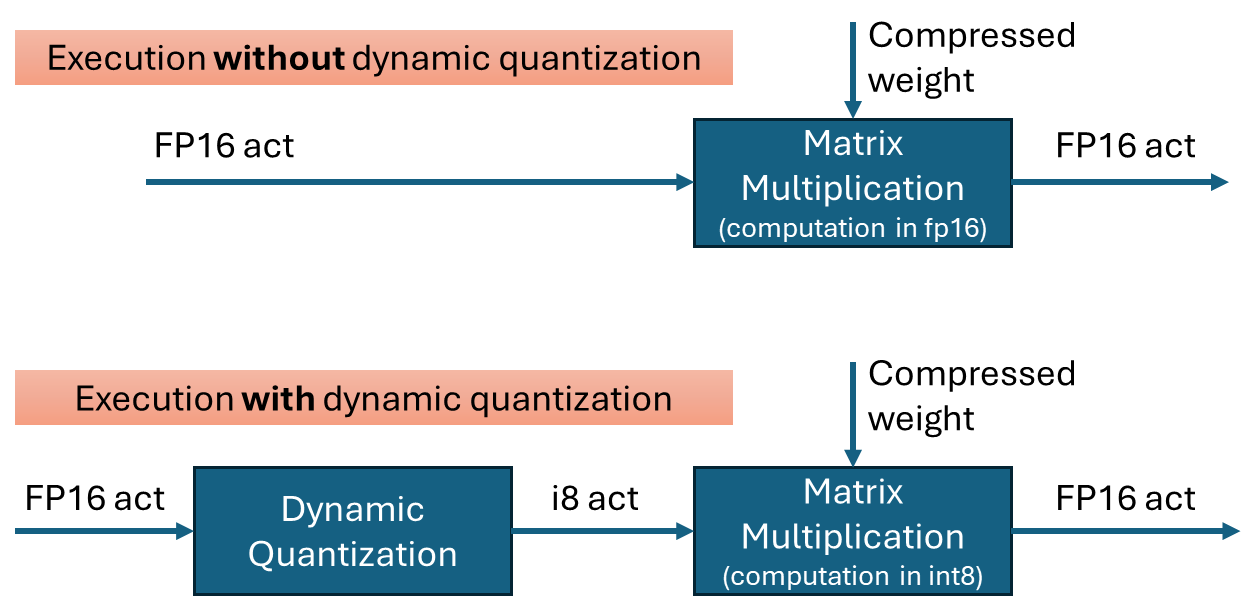

Model z dynamiczną kwantyzacją vs statyczną może się różnić rangem (clipping range). Często na korzyść accuracy dla modelu z dynamiczną.

In [11]:
import torch.quantization
from transformers import AutoTokenizer, AutoModelForCausalLM

torch.backends.quantized.engine = "qnnpack"

model_id = "gpt2-xl"

model = AutoModelForCausalLM.from_pretrained(model_id)
tokenizer = AutoTokenizer.from_pretrained(model_id)
tokenizer.pad_token = tokenizer.eos_token

quantized_model = torch.quantization.quantize_dynamic(
    model,
    {torch.nn.Linear},
    dtype=torch.qint8
)

quantized_model

/var/folders/dz/k1yrw7ln77l1qks16zv0lh7w0000gn/T/ipykernel_60516/1179417947.py:12: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized_model = torch.quantization.quantize_dynamic(


GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1600)
    (wpe): Embedding(1024, 1600)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-47): 48 x GPT2Block(
        (ln_1): LayerNorm((1600,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=4800, nx=1600)
          (c_proj): Conv1D(nf=1600, nx=1600)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1600,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=6400, nx=1600)
          (c_proj): Conv1D(nf=1600, nx=6400)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1600,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): DynamicQuantizedLinear(in_features=1600, out_features=50257, dtype=torch.qint8, qscheme=torch.per_ten

## Post-training quantization (PTQ) vs Quantization-aware training (QAT)

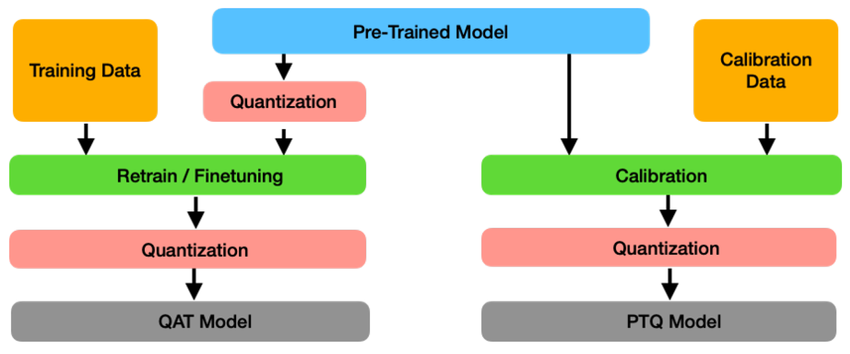

PTQ - kwantyzujemy gotowy, wytrenowany model -> chcemy przyspieszyć działanie lub zmniejszyć rozmiar modelu

QAT - kwantyzacja podczas trenowania lub fine-tuningu modelu -> lepsze wyniki ale bardzo kosztowna

# Zadania

## Zadanie 1

Skwantyzuj poniższy model różnymi typami kwantyzacji, porównaj wyniki z podwójną kwantyzacją (use_double_quant), poeksperymentuj ze zmianą danych do obliczeń (compute dtype)

Sprawdź czas generowania i jakość tekstu (na dowolnym pytaniu do modelu).

Porównaj wyniki z oryginalnym modelem w pełnej precyzji.

Uzupełnij tabelę wynikami i zanotuj wnioski.


In [12]:
model_id = "bigscience/bloom-560m"

In [13]:
import time
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

tokenizer = AutoTokenizer.from_pretrained(model_id)
prompt = "What is the most expensive cheese in the world?"

def test_model(model, name):
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    start = time.time()
    output = model.generate(**inputs, max_length=100)
    gen_time = time.time() - start

    print(f"=== {name}")
    print(f"Rozmiar: {model.get_memory_footprint() / 1024**2:.1f} MB")
    print(f"Czas: {gen_time:.2f} s")
    print(tokenizer.decode(output[0], skip_special_tokens=True))
    print()

# 4-bit: NF4/FP4 | compute dtype float16/32 | double quant True/False
for quant_type in ["nf4", "fp4"]:
    for compute_dtype in [torch.float16, torch.float32]:
        for double_quant in [True, False]:
            config = BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_quant_type=quant_type,
                bnb_4bit_use_double_quant=double_quant,
                bnb_4bit_compute_dtype=compute_dtype,
            )
            model = AutoModelForCausalLM.from_pretrained(model_id, quantization_config=config)
            test_model(model, f"{quant_type}, double quant={double_quant}, compute_dtype={compute_dtype}")

# 8-bit
model_8bit = AutoModelForCausalLM.from_pretrained(model_id, quantization_config=BitsAndBytesConfig(load_in_8bit=True))
test_model(model_8bit, "load_in_8bit")

# Pełna precyzja float32
model_fp32 = AutoModelForCausalLM.from_pretrained(model_id, dtype=torch.float32)
test_model(model_fp32, "float32")

=== nf4, double quant=True, compute_dtype=torch.float16
Rozmiar: 634.6 MB
Czas: 10.98 s
What is the most expensive cheese in the world? The answer is a cheese that is made from the same cheese as the most expensive cheese in the world. The most expensive cheese in the world is the cheese that is made from the same cheese as the most expensive cheese in the world. The most expensive cheese in the world is the cheese that is made from the same cheese as the most expensive cheese in the world. The most expensive cheese in the world is the cheese that is made from the same cheese

=== nf4, double quant=False, compute_dtype=torch.float16
Rozmiar: 634.6 MB
Czas: 9.27 s
What is the most expensive cheese in the world? The answer is a cheese that is made from the same cheese as the most expensive cheese in the world. The most expensive cheese in the world is the cheese that is made from the same cheese as the most expensive cheese in the world. The most expensive cheese in the world is the chee

| Model / konfiguracja                                                | Rozmiar modelu | Czas generowania 100 tokenów (max_length=100) | Subiektywna jakość tekstu (można wkleić przykłady) |
| ------------------------------------------------------------------- | -------------- | --------------------------------------------- | -------------------------------------------------- |
| BitsAndBytesConfig - NF4, double quant=True, compute_dtype=float16  | 634.6 MB | 10.98 s | Słaba (powtarza tekst "cheese that is made from the same cheese as the most expensive cheese in the world")  |
| BitsAndBytesConfig - NF4, double quant=False, compute_dtype=float16 | 634.6 MB | 9.27 s | Tak samo jak wyżej |
| BitsAndBytesConfig - NF4, double quant=True, compute_dtype=float32  | 635.0 MB | 13.43 s | Tak samo jak wyżej |
| BitsAndBytesConfig - NF4, double quant=False, compute_dtype=float32 | 635.0 MB | 12.58 s | Tak samo jak wyżej |
| BitsAndBytesConfig - FP4, double quant=True, compute_dtype=float16  | 634.6 MB | 10.73 s | Słaba,trochę inny tekst niż NF4 (powtarza "the most expensive cheese in the world is the most expensive cheese in the world") |
| BitsAndBytesConfig - FP4, double quant=False, compute_dtype=float16 | 634.6 MB | 9.13 s | Najgorsza, cały czas powtarza ten sam tekst |
| BitsAndBytesConfig - FP4, double quant=True, compute_dtype=float32  | 635.0 MB | 13.61 s | Taki sam tekst jak FP4, double quant=True, float16 |
| BitsAndBytesConfig - FP4, double quant=False, compute_dtype=float32 | 635.0 MB | 13.36 s | Taki sam tekst jak FP4, double quant=True, float16 |
| load_in_8bit - 8-bit                                                | 778.6 MB | 8.81 s | Trochę lepsza, ale też powtarza tekst |
| Pełna precyzja float32                                              | 2133.2 MB | 2.45 s | Inny początek w porównaniu z pozostałemy modelame, ale też powtarza potem tekst w odpowiedzi |

Uzupełnij tabelę i zanotuj wnioski (jeśli komuś nie wygodnie uzupełniać tabelki na colabie, mozna wkleić screena)

Wnioski:

> Kwantyzacja 4-bit zmniejszyła model z +- 2.1 GB do +- 635 MB, a 8-bit do +- 780 MB.
>
> Na moim Macu czemuś wszystkie skwantyzowane wersje generowały wolniej niż oryginał. NF4 dawał ten sam tekst we wszystkich wariantach, FP4 częściej się powtarzał, ale tak naprawdę wszystkie odpowiedzi są słabe i się powtarzają, imo przez to że początkowy model i tak jest dość mały